<a href="https://colab.research.google.com/github/XanderPatterson/4487-IS-Class-Labs/blob/main/assignment_14_api.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IS 4487 Assignment 14: Exploring APIs with yfinance

In this assignment, you will:
- Choose an industry you're interested in (such as tech, airlines, or retail)
- Use the `yfinance` Python package as an API to collect historical stock price data
- Clean and prepare the data for analysis
- Explore trends, volatility, and relationships between companies
- Summarize your findings and recommendation in a business memo

## Why This Matters

APIs (Application Programming Interfaces) allow businesses to pull live, real-world data from external sources directly into their analytics tools. Financial analysts, investment firms, and business leaders use APIs like `yfinance` to monitor company performance, assess market trends, and build models based on dynamic data.

This assignment helps you gain hands-on experience with one of the most common API workflows in business analytics: fetching, cleaning, analyzing, and interpreting financial data to support better decision-making.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_14_api.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>



## Step 1: Choose an Industry and Find Company Ticker Symbols

Visit the following website to explore U.S. stock sectors and industries:  
https://www.tradingview.com/markets/stocks-usa/sectorandindustry-sector/

### Do the following
Choose one industry you are interested in (for example: Airlines, Technology, Fast Food, Retail, Energy, etc.).  
Write the names and ticker symbols of 4 public companies in that industry.

**Example:**
- Industry: Technology  
- Tickers: AAPL, MSFT


Industry: Fast Food

McDonald's (MCD)

Yum! Brands (YUM)

The Wendy's Company (WEN)

Restaurant Brands International (QSR)

In [21]:
industry = ['Fast Food']
industry_name = ['Mcdonalds','Yum! Brands','Wendys','Resturant Brands International']
tickers = ['MCD', 'YUM', 'WEN', 'QSR']

## Step 2: Use yfinance to Collect Historical Stock Data

Follow the steps below to use the `yfinance` API to collect historical stock price data.

### Do the following

1. Make sure the `yfinance` package is installed by running the code cell below.
2. Import any additional Python libraries that you might need to explore or visualize the data.
3. Use the `yf.download()` function to pull **5 years of daily adjusted close prices** for the companies you selected in Step 1.
    - Choose a start date and an end date that span the past 5 years (e.g., `"2020-01-01"` to `"2025-12-31"`).
    - Only select the **'High'** column, which represents the daily high
4. Preview the first few rows of the dataset using `.head()` to confirm that the data has loaded correctly.



In [14]:
# Import necessary libraries
!pip install yfinance

import yfinance as yf
import pandas as pd

In [15]:
# Download adjusted close prices
df = yf.download(tickers, start="2020-01-01", end="2025-01-01")['High']

/tmp/ipykernel_3913/379398263.py:2: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(tickers, start="2020-01-01", end="2025-01-01")['High']
[*********************100%***********************]  4 of 4 completed


In [16]:
df.head()

Ticker,MCD,QSR,WEN,YUM
Date,,,,
2020-01-02,171.413391,51.143686,17.128428,90.024550
2020-01-03,171.199954,51.214551,17.227971,89.865969
2020-01-06,173.095061,50.710659,17.044204,89.680976
2020-01-07,173.018212,50.553210,16.937008,90.068573
2020-01-08,176.441406,49.576938,16.891062,90.720511


## Step 3: Clean the Data

The data you pulled may contain missing values.

### Do the following

1. Check the dataset for missing values using `.isnull().sum()`.
2. Fill any missing values using a forward fill method.
3. Recheck for missing values to confirm they have been handled.



In [17]:
print("Missing values before filling:")
print(df.isnull().sum())

df = df.ffill()

print("\nMissing values after forward fill:")
print(df.isnull().sum())

Missing values before filling:
Ticker
MCD    0
QSR    0
WEN    0
YUM    0
dtype: int64

Missing values after forward fill:
Ticker
MCD    0
QSR    0
WEN    0
YUM    0
dtype: int64


## Step 4: Calculate Daily Returns

To better understand price movement, we will calculate the daily percentage change for each stock.

### Do the following

1. Use the `.pct_change()` method to calculate daily returns.
2. Drop any rows with missing values that may result from this calculation.
3. Preview the returns DataFrame to confirm it's correct.


In [18]:
returns = df.pct_change()

returns = returns.dropna()

returns.head()

Ticker,MCD,QSR,WEN,YUM
Date,,,,
2020-01-03,-0.001245,0.001386,0.005812,-0.001762
2020-01-06,0.011070,-0.009839,-0.010667,-0.002059
2020-01-07,-0.000444,-0.003105,-0.006289,0.004322
2020-01-08,0.019785,-0.019312,-0.002713,0.007238
2020-01-09,0.012966,0.010640,-0.001360,0.010099


## Step 5: Explore the Data Visually and Statistically

In this step, you will create visualizations and metrics to help understand stock behavior. Don’t interpret or explain anything here — just create the outputs so you can use them in your reflection later.

### Do the following
1. Create a line chart showing stock prices over the 5-year period.
2. Calculate the standard deviation of daily returns for each stock (volatility).
3. Create a correlation matrix of the daily returns between companies.




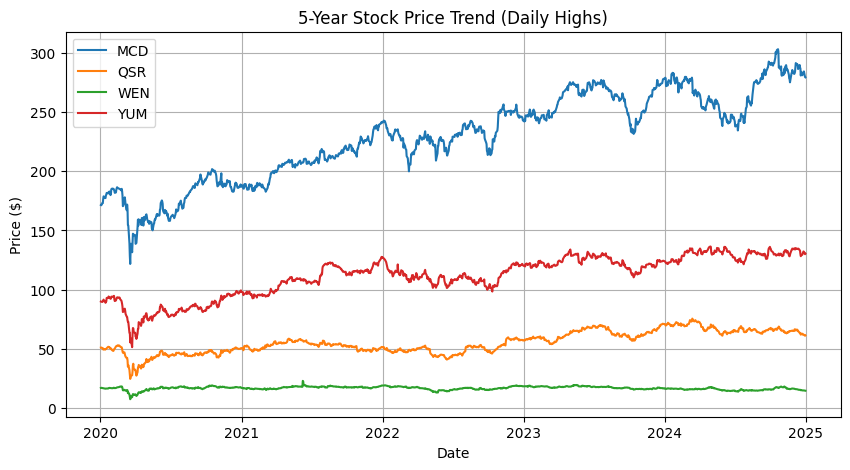

--- Daily Return Volatility (Standard Deviation) ---
Ticker
MCD    0.012334
QSR    0.018300
WEN    0.022410
YUM    0.015265
dtype: float64

--- Daily Returns Correlation Matrix ---
Ticker       MCD       QSR       WEN       YUM
Ticker                                        
MCD     1.000000  0.572747  0.526214  0.668377
QSR     0.572747  1.000000  0.546556  0.610161
WEN     0.526214  0.546556  1.000000  0.525831
YUM     0.668377  0.610161  0.525831  1.000000


In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(df)
plt.title('5-Year Stock Price Trend (Daily Highs)')
plt.xlabel('Date')
plt.ylabel('Price ($)')
plt.legend(df.columns)
plt.grid(True)
plt.show()

print("--- Daily Return Volatility (Standard Deviation) ---")
print(returns.std())

print("\n--- Daily Returns Correlation Matrix ---")
print(returns.corr())

## Step 6: Write a Stakeholder Recommendation Memo

Now that you’ve completed your analysis, it’s time to turn your work into a clear, professional memo for a business audience.

### Scenario

You’ve been asked by a stakeholder (an investor, executive, or client) to evaluate whether it's a good time to invest in a particular industry. They’ve asked you to use recent stock performance data from several leading companies in that industry to help guide their decision.

### Your Task

Use the results from your code in Steps 2–5 to write a **multi-paragraph business memo** that:

1. **Introduces the industry you analyzed** and names the companies you included.
2. **Summarizes major trends** you observed in the stock prices over the last 5 years.
3. **Discusses key metrics**, such as volatility and correlations between companies.
4. **Presents your investment recommendation** — based on your evidence — and explains why you would or wouldn’t advise investing in this industry now.
5. **Suggests future analytics or data sources** that could strengthen or update your recommendation going forward.

This final section should show that you understand how real-world decisions evolve. Think about:
- What **additional data** might help (e.g., earnings reports, economic indicators, sentiment analysis)?
- What **types of models** could be applied (e.g., forecasting, classification, risk modeling)?
- How often should the analysis be updated?

### Format & Expectations

- Write **2–4 paragraphs** in business memo format (not bullet points).
- Use **specific, data-driven evidence** from your own analysis.
- Keep your writing professional and clear — imagine your reader is a client or executive, not a data analyst.
- Your memo should be written **entirely in your own words**. Do not copy from examples, online sources, or AI tools. Your writing should reflect your understanding and your interpretation of the results.
- You do not need to include charts in the memo — the code cells above already display them.



### ✍️ Add memo here:

Memo: This analysis looks at the performance of the fast food industry over a 5 years, from January 2020 to January 2025, using daily high stock prices. The four companies included in the analysis are McDonald's (MCD), Yum! Brands (YUM), Restaurant Brands International (QSR), and The Wendy's Company (WEN). Overall, the industry showed steady performance during this period. Larger companies like McDonald's and Yum! Brands had more consistent long-term growth, while Wendy's and QSR experienced more price changes and slower overall growth.

Looking at the statistics, McDonald's was the most stable stock, with the lowest daily return volatility of 1.23%. Yum! Brands followed with a volatility of 1.53%. Wendy's had the highest volatility at 2.24%, meaning its stock price changed more often and had larger daily movements. The correlation analysis also showed that all four stocks had positive relationships, with McDonald's and Yum! Brands having the highest correlation at 0.668. Since all the correlations were above 0.52, the stocks generally moved in the same direction due to similar economic factors, including inflation, food costs, and labor expenses. Normally in a portfolio you would want the correlation to be negative, but in this case it makes sense because they are all in the same industry. Based on these results, McDonald's and Yum! Brands appear to be better choices for investors looking for more stable investments and long-term growth. Owning all four stocks may provide limited diversification because their prices tend to move together.

For future analysis, it would be helpful to update the data every quarter after companies release their earnings reports. This really shows the volatility of a stock. Adding information such as same store sales growth, consumer spending trends, and changes in food and commodity prices could give a better understanding of how each company is performing. Other methods, such as Moving Averages or Standard comparisons, could also be used to help predict future stock prices and could help to better understand possible investment risks.

## Submission Instructions
✅ Checklist:
- All code cells run without error
- All markdown responses are complete
- Submit on Canvas as instructed

In [ ]:
!jupyter nbconvert --to html "assignment_14_api.ipynb"